# 09 — Model Evaluation on the Held-out Test Period
Test period: 2026-06-03 → 2026-10-12 (never used for training, tuning or selection). The selected
MAF-Net checkpoint is the seed with the highest **validation** macro-F1. Confidence intervals use a
site-block bootstrap (1 000 resamples of whole sites) to respect autocorrelation within a site.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 220)
from climatesense.utils import read_json
import platform, torch, sklearn
print("Executed:", pd.Timestamp.now().strftime("%Y-%m-%d %H:%M"), "| Python", platform.python_version(),
      "| torch", torch.__version__, "| sklearn", sklearn.__version__, "| pandas", pd.__version__)
def show(p, width=850):
    display(Image(filename=str(ROOT / p), width=width))

Executed: 2026-10-25 18:07 | Python 3.13.7 | torch 2.14.1+cu126 | sklearn 1.9.1 | pandas 3.1.0


In [2]:
mc = pd.read_csv(ROOT / "results/tables/model_comparison_h1.csv")
mc[["model","modalities","n_params","n_runs","val_macro_f1","accuracy","balanced_accuracy","macro_precision","macro_recall","macro_f1","macro_f1_std","weighted_f1","roc_auc_macro_ovr","pr_auc_macro","train_time_s"]].round(4)

,model,modalities,n_params,n_runs,val_macro_f1,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,macro_f1_std,weighted_f1,roc_auc_macro_ovr,pr_auc_macro,train_time_s
0,Persistence (today's class),label history,0,1,NaN,0.7976,0.7270,0.7261,0.7270,0.7265,0.0000,0.7976,0.8218,0.5952,0.0000
1,Majority class,—,0,1,NaN,0.6144,0.2500,0.1536,0.2500,0.1903,0.0000,0.4676,0.5000,0.2500,0.0000
2,Site-month climatology,—,0,1,NaN,0.6140,0.5859,0.4961,0.5859,0.5192,0.0000,0.6369,0.7272,0.4100,0.0000
3,Logistic regression,C+A+D (aggregated),948,1,0.7291,0.8015,0.7270,0.7336,0.7270,0.7297,0.0000,0.8033,0.9384,0.7604,33.5362
4,Random forest,C+A+D (aggregated),4016074,1,0.7405,0.8059,0.7392,0.7415,0.7392,0.7398,0.0000,0.8076,0.9445,0.7890,63.0108
5,Gradient boosting (HistGB),C+A+D (aggregated),30500,1,0.7397,0.8023,0.7436,0.7250,0.7436,0.7337,0.0000,0.8052,0.9444,0.7874,116.9899
6,MLP (sklearn),C+A+D (aggregated),94084,1,0.7181,0.7922,0.6852,0.7226,0.6852,0.7004,0.0000,0.7835,0.9357,0.7636,54.2020
7,"MAF-Net (proposed, attention fusion)",C+A+D+ctx,33268,5,0.7422,0.8063,0.7470,0.7382,0.7470,0.7414,0.0026,0.8073,0.9410,0.7854,326.8507
8,MAF-Net w/o attention (concat fusion),C+A+D+ctx,21652,5,0.7406,0.8012,0.7468,0.7321,0.7468,0.7375,0.0038,0.8045,0.9391,0.7785,171.0839
9,GRU (tuned),C+A+D (single stream)+ctx,49860,5,0.7410,0.7982,0.7536,0.7290,0.7536,0.7391,0.0029,0.8036,0.9437,0.7843,78.9377


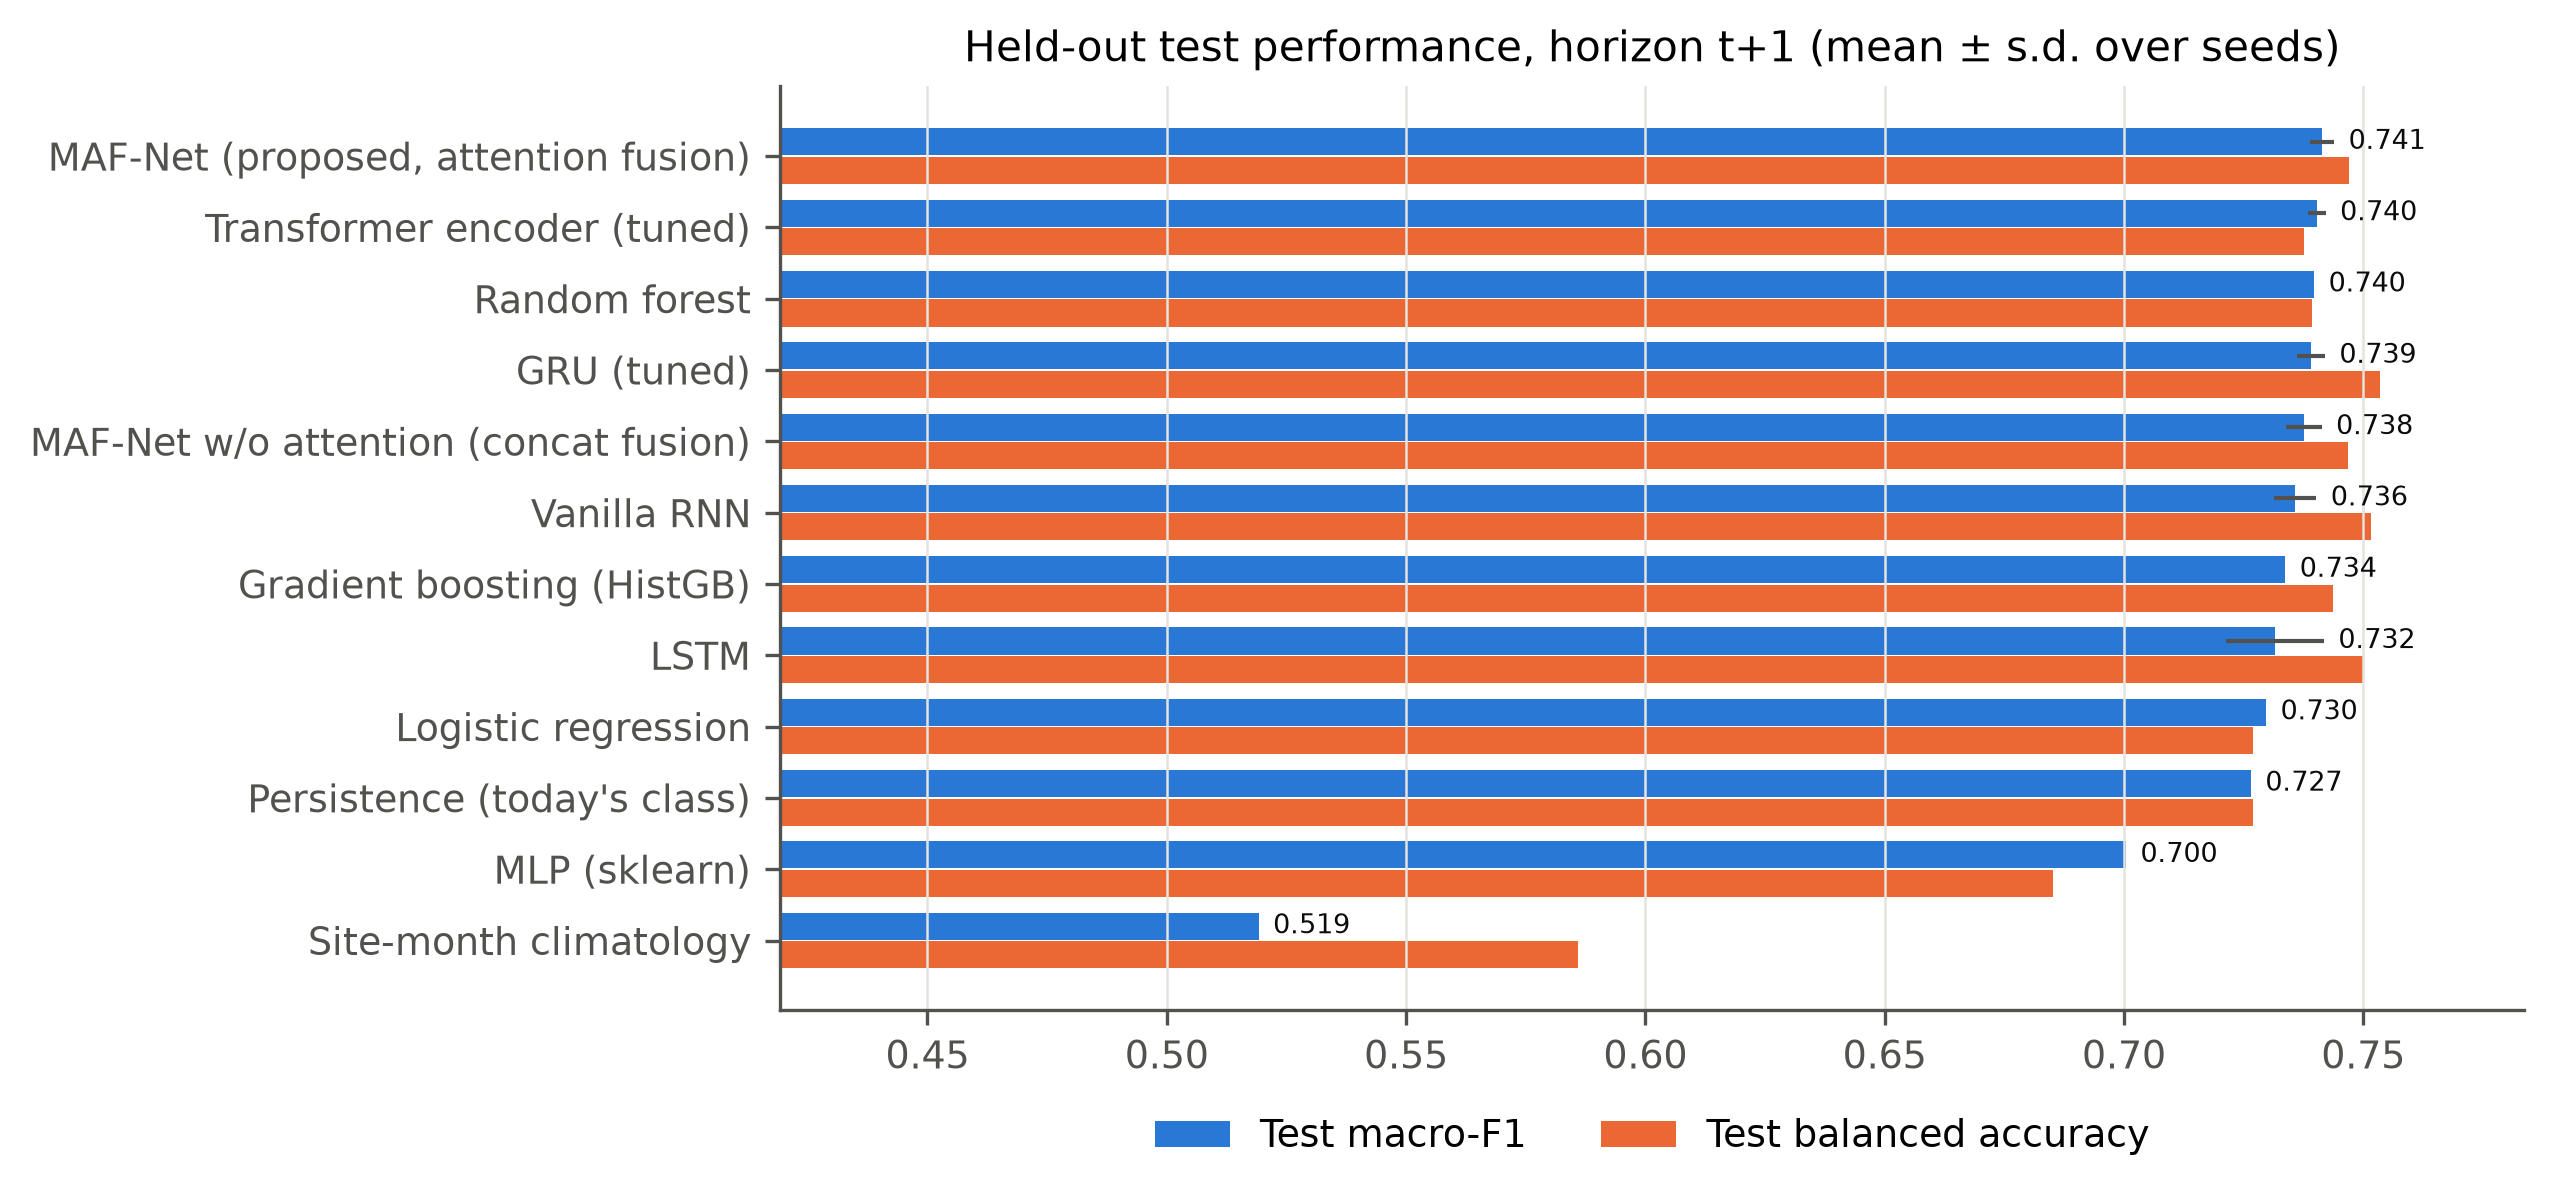

In [3]:
show("results/figures/model_comparison.png", 750)

### Selected MAF-Net: confusion matrices, ROC and PR curves

In [4]:
st = read_json(ROOT / "results/metrics/selected_model_test.json")
m = st["test_metrics"]; print("selected run:", st["selected_run"])
print({k: round(m[k], 4) for k in ["accuracy","balanced_accuracy","macro_precision","macro_recall","macro_f1","weighted_f1","roc_auc_macro_ovr","pr_auc_macro","log_loss","brier","quadratic_kappa"]})
print("95% CI macro-F1:", np.round(st["ci95_macro_f1_site_block_bootstrap"], 4), "| accuracy:", np.round(st["ci95_accuracy_site_block_bootstrap"], 4))
from climatesense.labeling.compound_risk import CLASS_NAMES
pd.DataFrame(m["per_class"]).T.rename(index=dict(zip(map(str, range(4)), CLASS_NAMES))).round(3)

selected run: final-mafnet-4ac9637255
{'accuracy': 0.807, 'balanced_accuracy': 0.7436, 'macro_precision': 0.7416, 'macro_recall': 0.7436, 'macro_f1': 0.7415, 'weighted_f1': 0.8084, 'roc_auc_macro_ovr': 0.9411, 'pr_auc_macro': 0.7871, 'log_loss': 0.5461, 'brier': 0.3122, 'quadratic_kappa': 0.8741}
95% CI macro-F1: [0.7139 0.7616] | accuracy: [0.7842 0.8285]


,precision,recall,f1,support,roc_auc,pr_auc
Low,0.906,0.897,0.901,13020.0,0.952,0.969
Moderate,0.624,0.618,0.621,4576.0,0.874,0.646
High,0.588,0.677,0.629,2003.0,0.950,0.631
Critical,0.848,0.783,0.815,1593.0,0.988,0.901


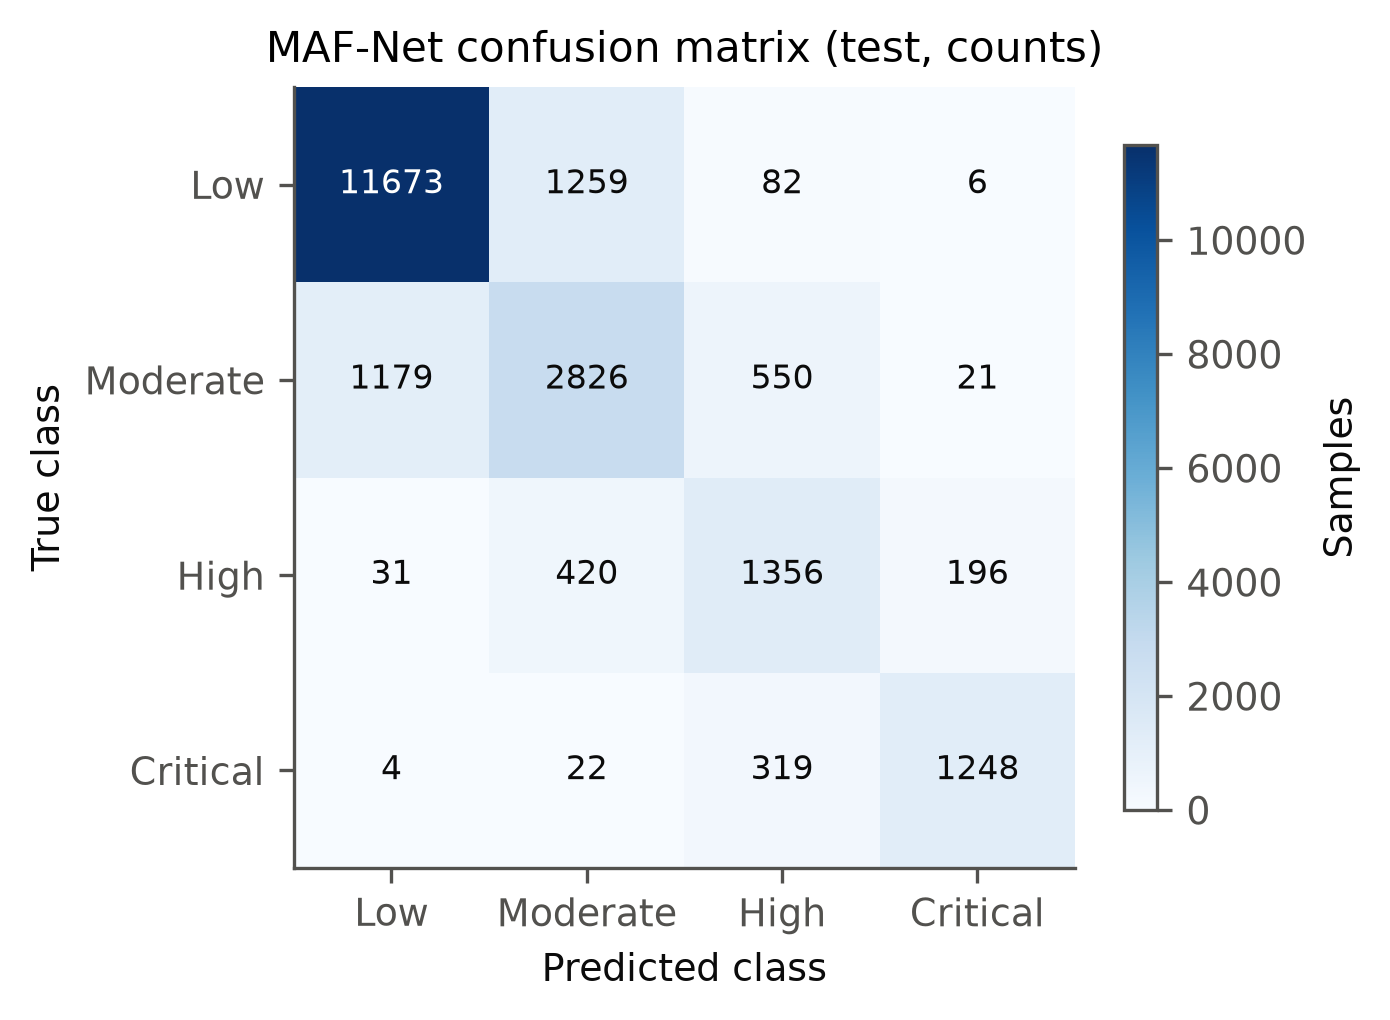

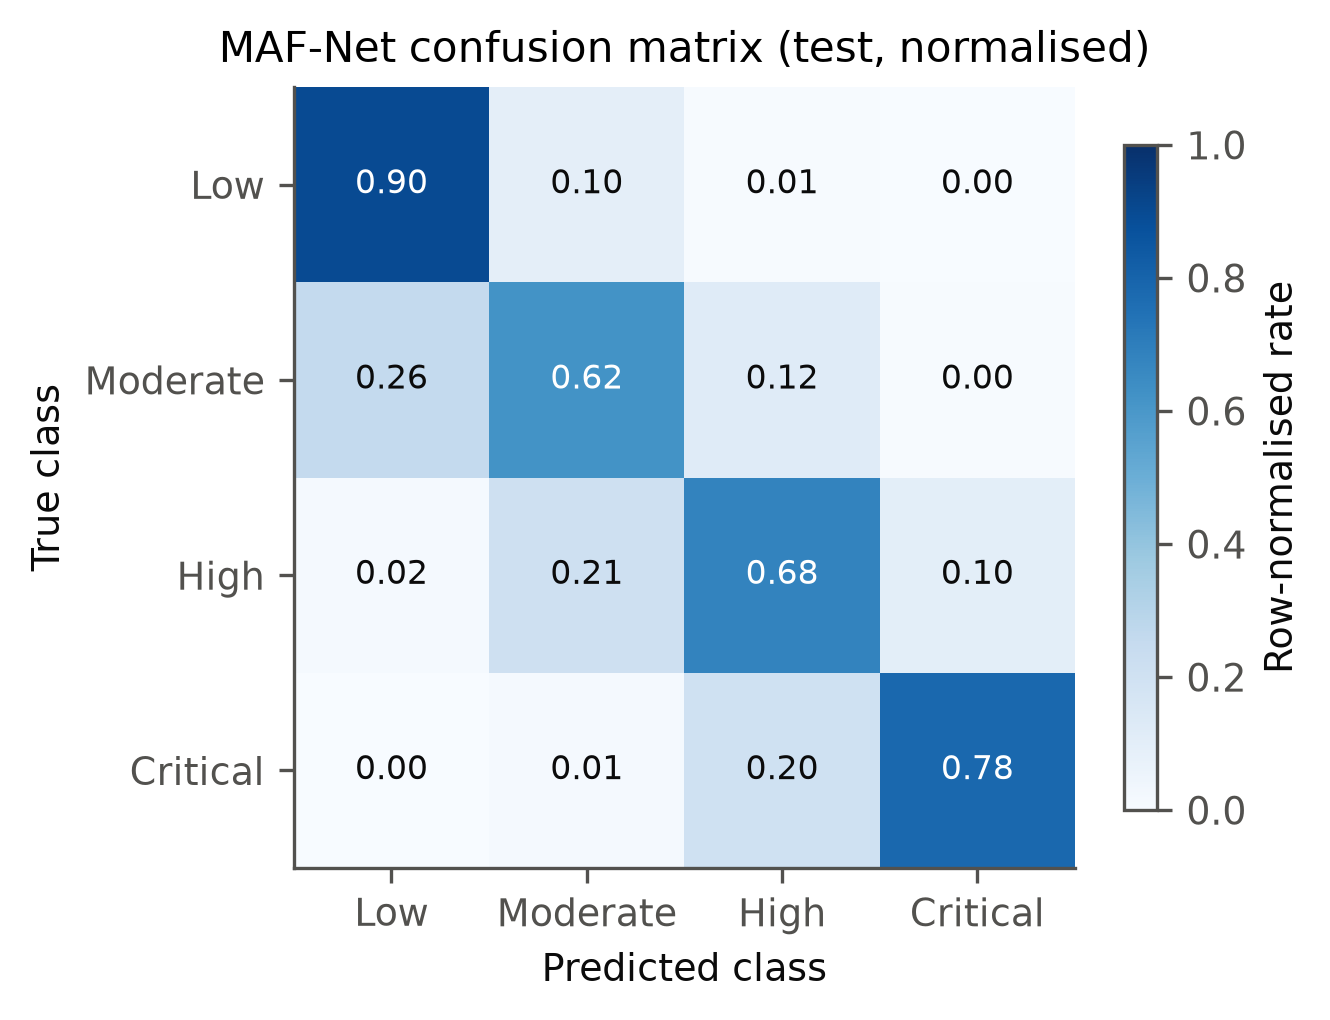

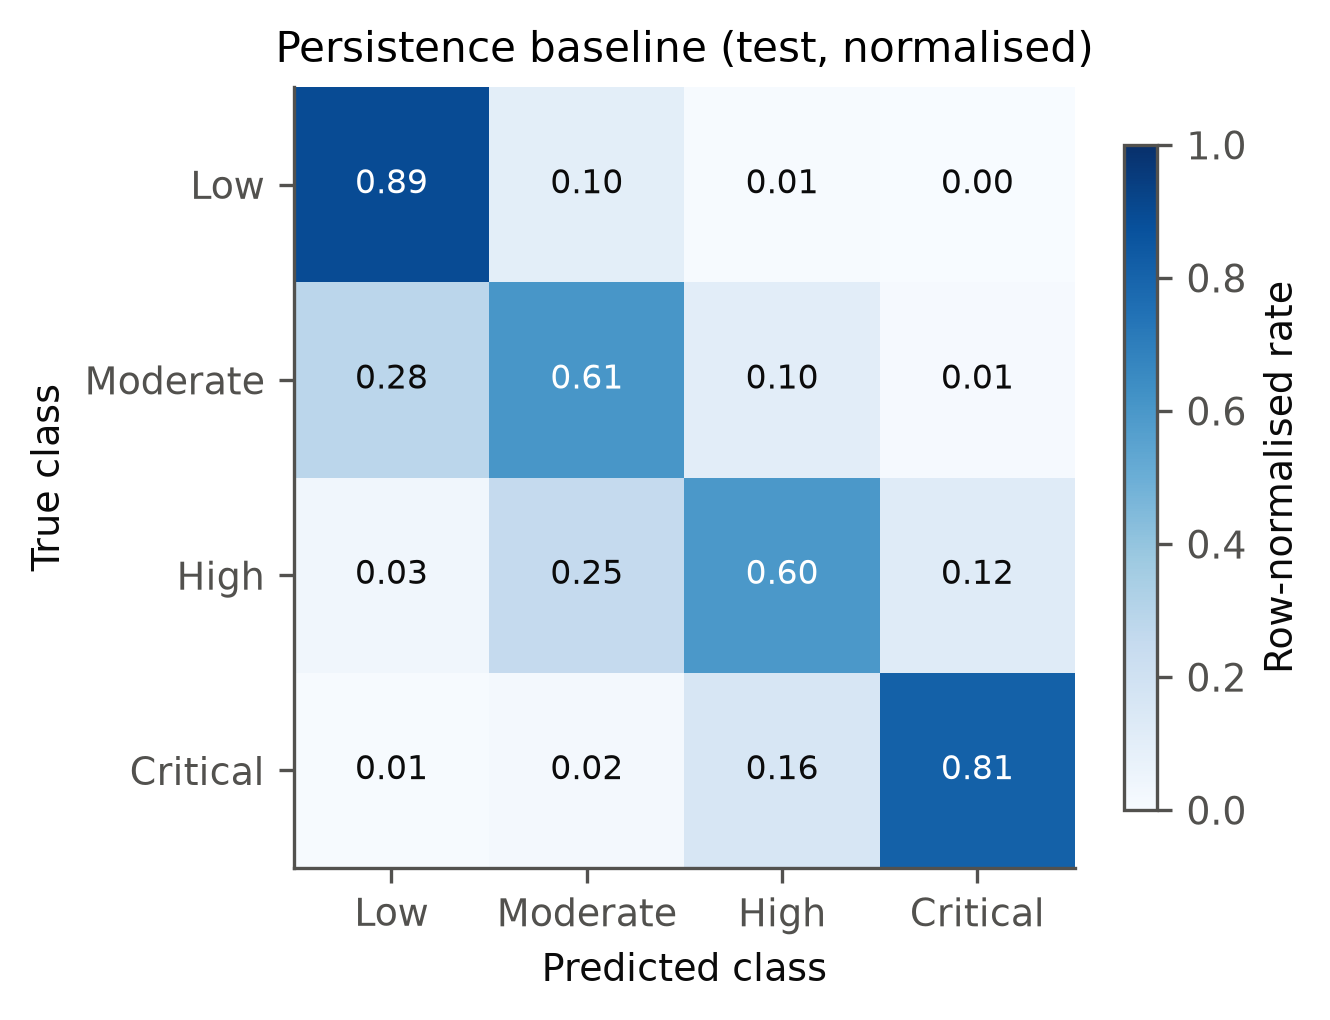

In [5]:
show("results/figures/confusion_matrix_raw.png", 420); show("results/figures/confusion_matrix_normalized.png", 420); show("results/figures/confusion_matrix_persistence.png", 420)

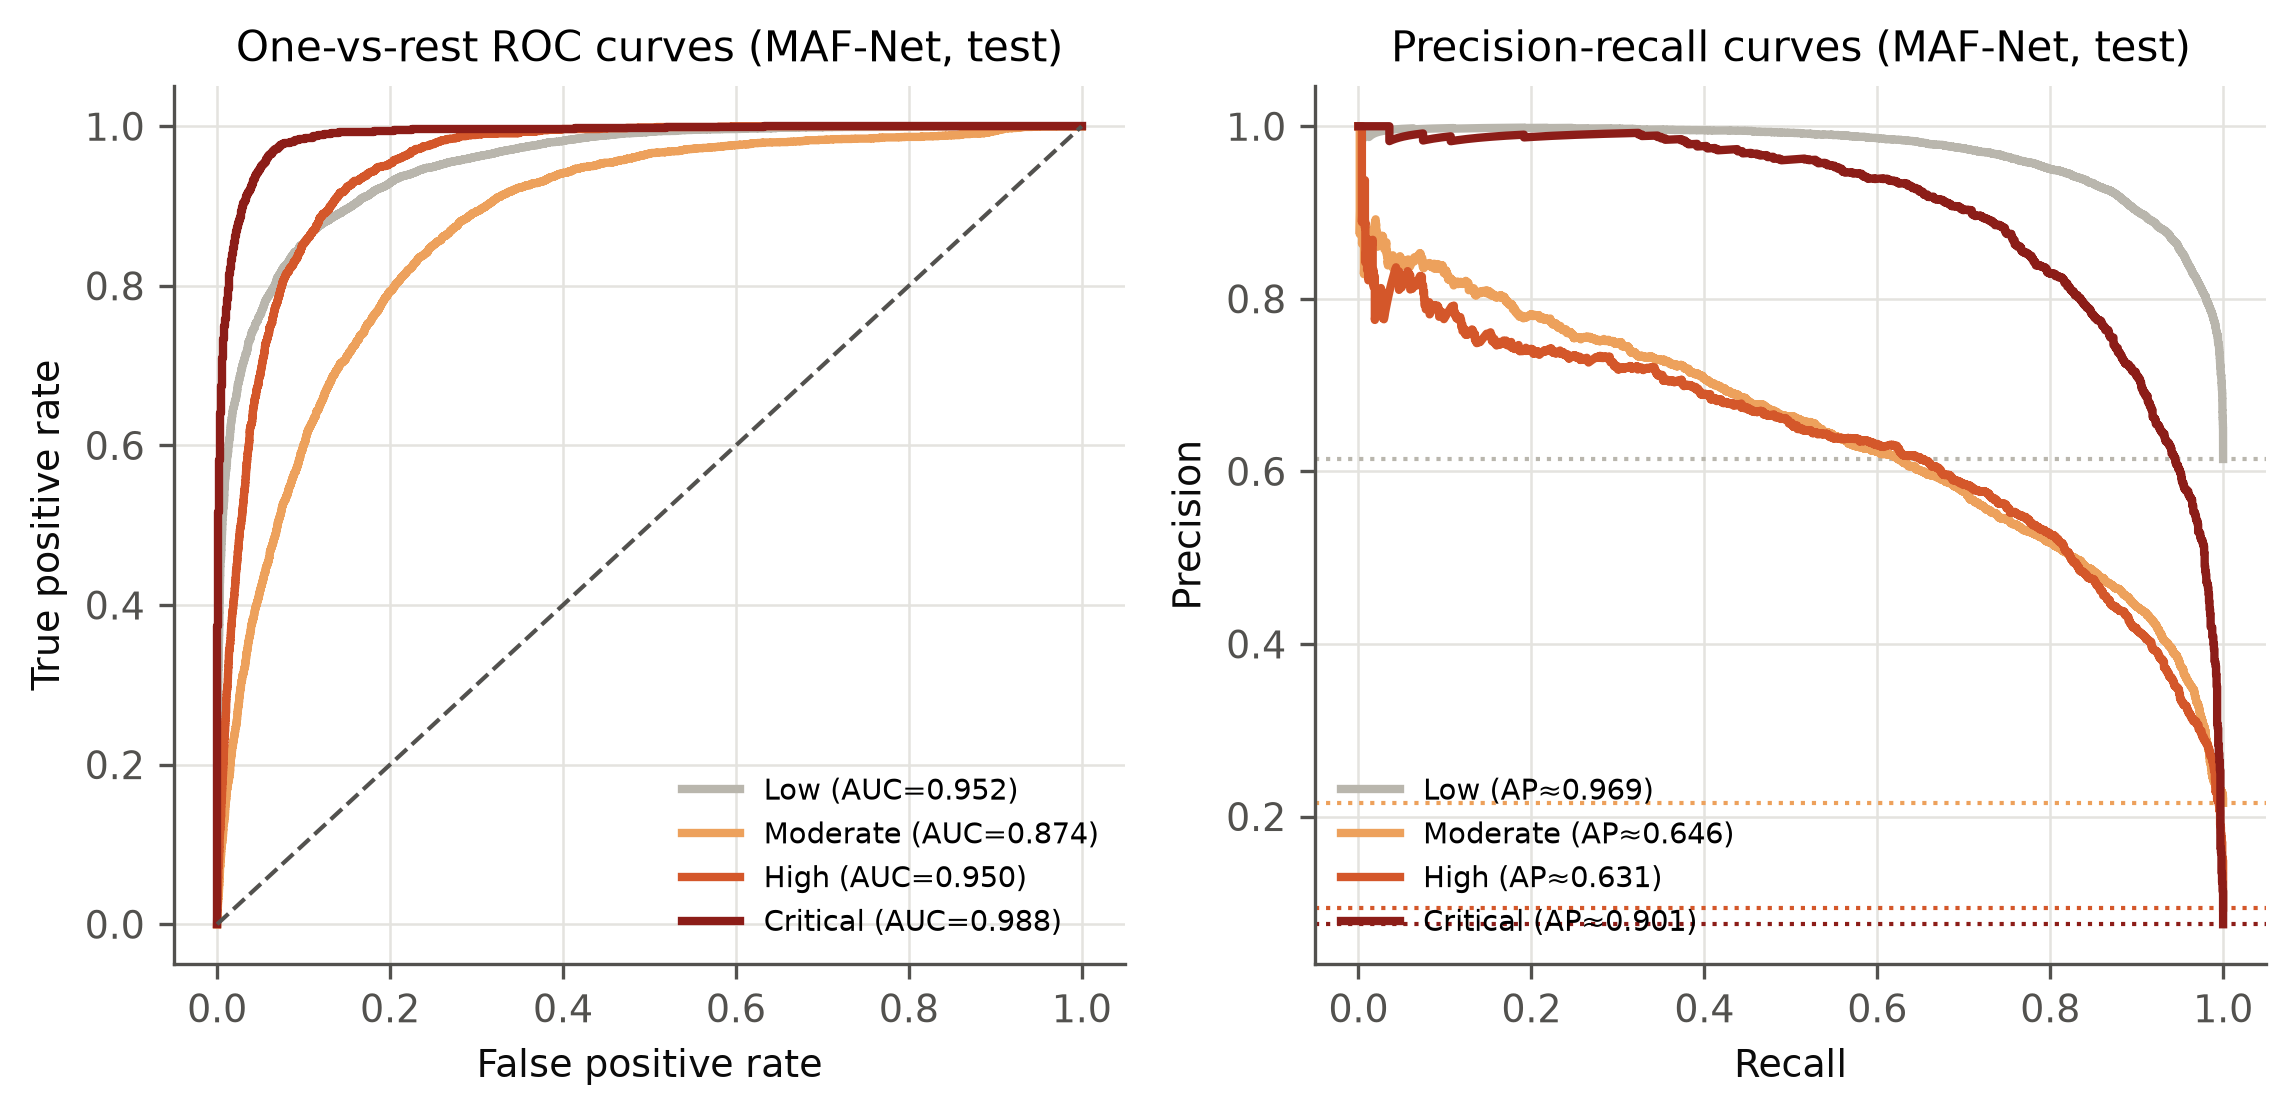

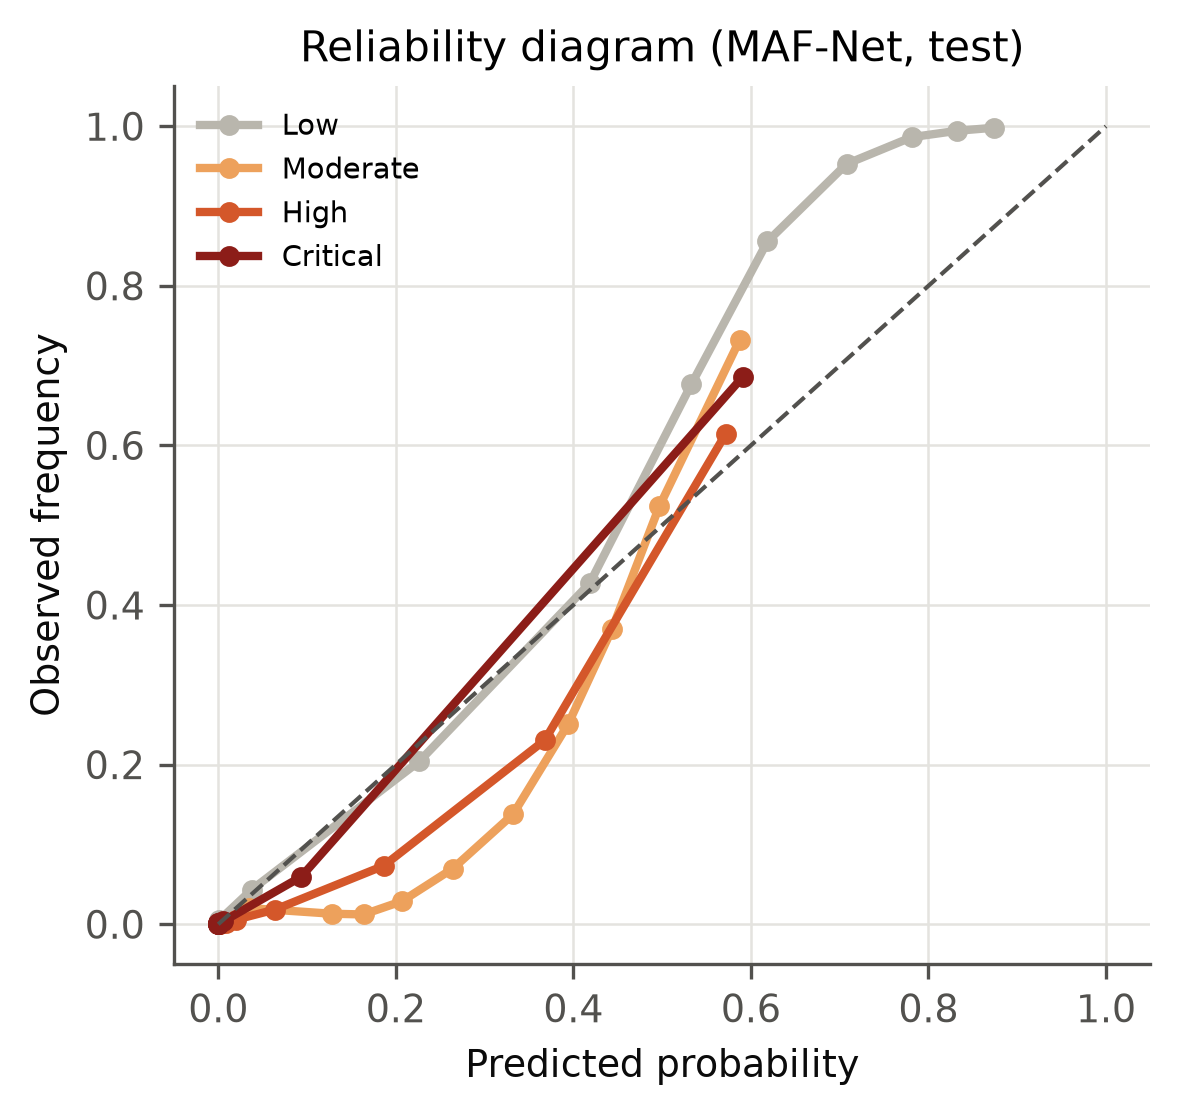

In [6]:
show("results/figures/roc_pr_curves.png"); show("results/figures/calibration.png", 420)

In [7]:
from sklearn.metrics import classification_report
d = np.load(ROOT / f"results/predictions/{st['selected_run']}_test.npz")
print(classification_report(d["y"], d["proba"].argmax(1), target_names=CLASS_NAMES, digits=3))

              precision    recall  f1-score   support

         Low      0.906     0.897     0.901     13020
    Moderate      0.624     0.618     0.621      4576
        High      0.588     0.677     0.629      2003
    Critical      0.848     0.783     0.815      1593

    accuracy                          0.807     21192
   macro avg      0.742     0.744     0.741     21192
weighted avg      0.811     0.807     0.808     21192



### Paired comparisons on identical test samples (site-block bootstrap of Δ macro-F1)

In [8]:
pd.DataFrame(st["paired_vs"]).T[["run","diff","ci95","p_diff_le_0"]]

,run,diff,ci95,p_diff_le_0
persistence,baseline-persistence_L14_h1,0.014926,"[0.006646, 0.022054]",0.001
hist_gradient_boosting,baseline-hist_gradient_boosting_L14_h1,0.007751,"[0.000763, 0.014983]",0.017
random_forest,baseline-random_forest_L14_h1,0.001713,"[-0.005287, 0.008582]",0.287
gru,final-gru-8efd03ecf9,0.002911,"[-0.003937, 0.009308]",0.194
mafnet_concat,final-mafnet-e514ce8b80,0.004916,"[-0.000581, 0.010888]",0.04
transformer,final-transformer-f0cd82ee4a,0.001024,"[-0.005198, 0.007057]",0.364


`diff` = macro-F1(MAF-Net) − macro-F1(other); `p_diff_le_0` is the bootstrap share of resamples
in which MAF-Net is not better. These are descriptive resampling statistics, not a formal
multiple-comparison-corrected significance test.

### Forecast horizon and spatial generalisation

,horizon,model,n_runs,accuracy,balanced_accuracy,macro_f1,macro_f1_std,roc_auc_macro_ovr
0,1,Persistence,1,0.7976,0.7270,0.7265,0.0000,0.8218
1,1,Gradient boosting,1,0.8023,0.7436,0.7337,0.0000,0.9444
2,1,MAF-Net,3,0.8075,0.7482,0.7426,0.0010,0.9412
3,1,GRU,3,0.7979,0.7553,0.7395,0.0040,0.9433
4,3,Persistence,1,0.7463,0.6562,0.6552,0.0000,0.7756
5,3,Gradient boosting,1,0.7726,0.6816,0.6769,0.0000,0.9268
6,3,MAF-Net,3,0.7715,0.7026,0.6879,0.0083,0.9219
7,3,GRU,3,0.7628,0.7131,0.6936,0.0091,0.9260
8,7,Persistence,1,0.7298,0.6326,0.6305,0.0000,0.7608
9,7,Gradient boosting,1,0.7615,0.6586,0.6566,0.0000,0.9181


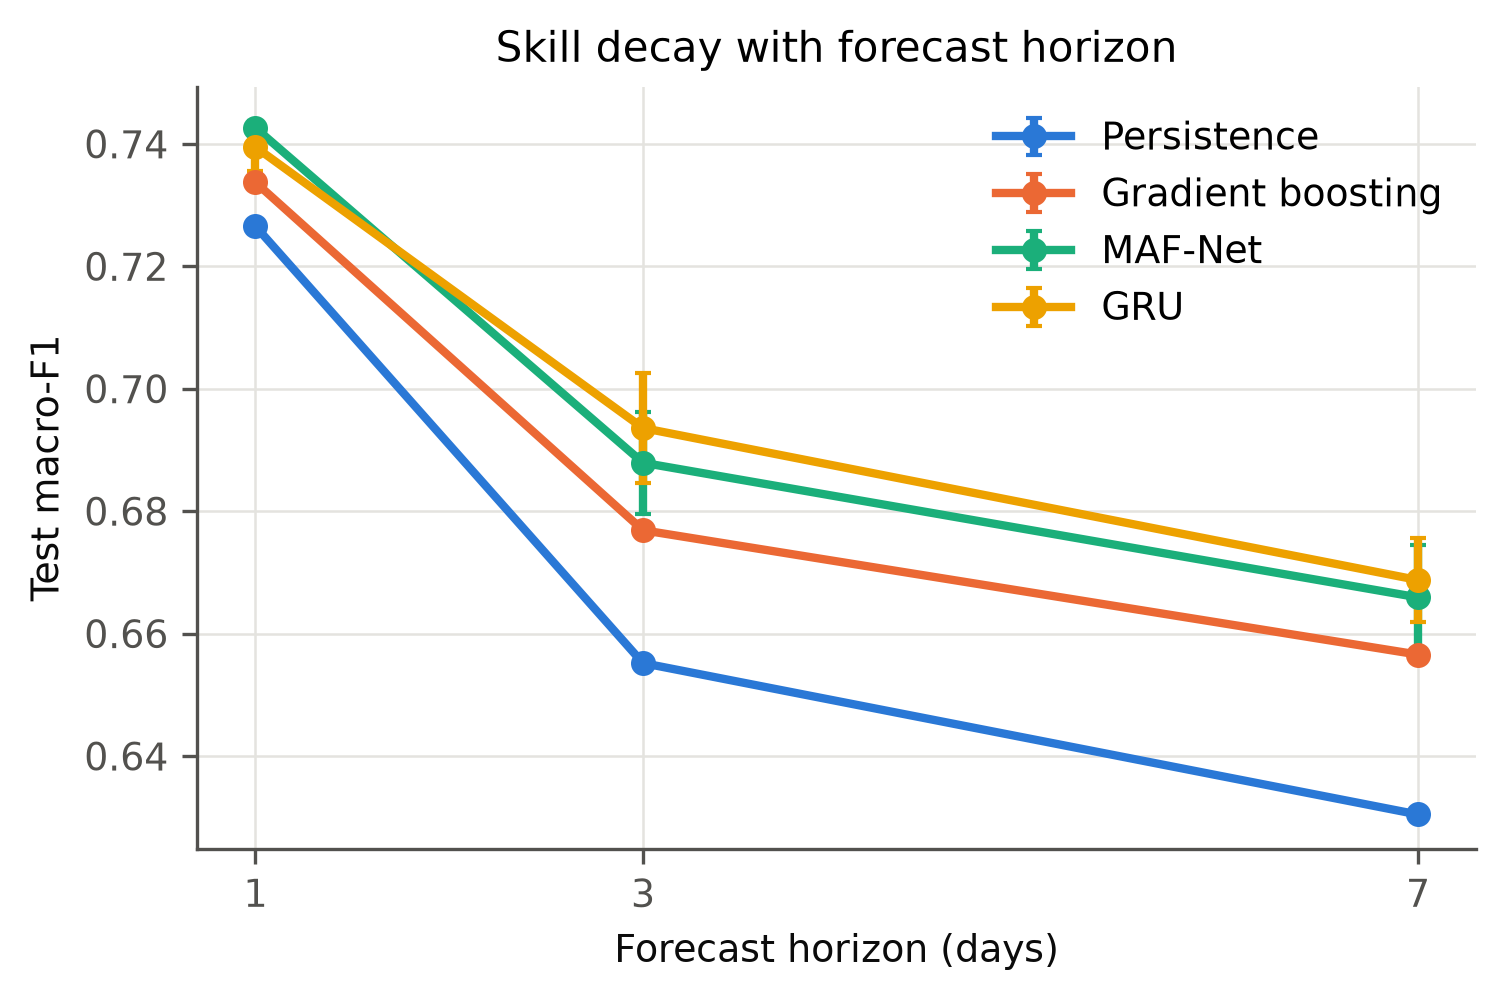

,model,heldout_macro_f1,heldout_macro_f1_std,heldout_balanced_accuracy,heldout_accuracy,seen_sites_macro_f1,seen_sites_balanced_accuracy
0,mafnet,0.7065,0.0058,0.7193,0.7375,0.7387,0.7453
1,gru,0.7089,0.0030,0.7326,0.7249,0.7395,0.7579
2,persistence,0.7133,NaN,0.7137,0.7547,NaN,NaN


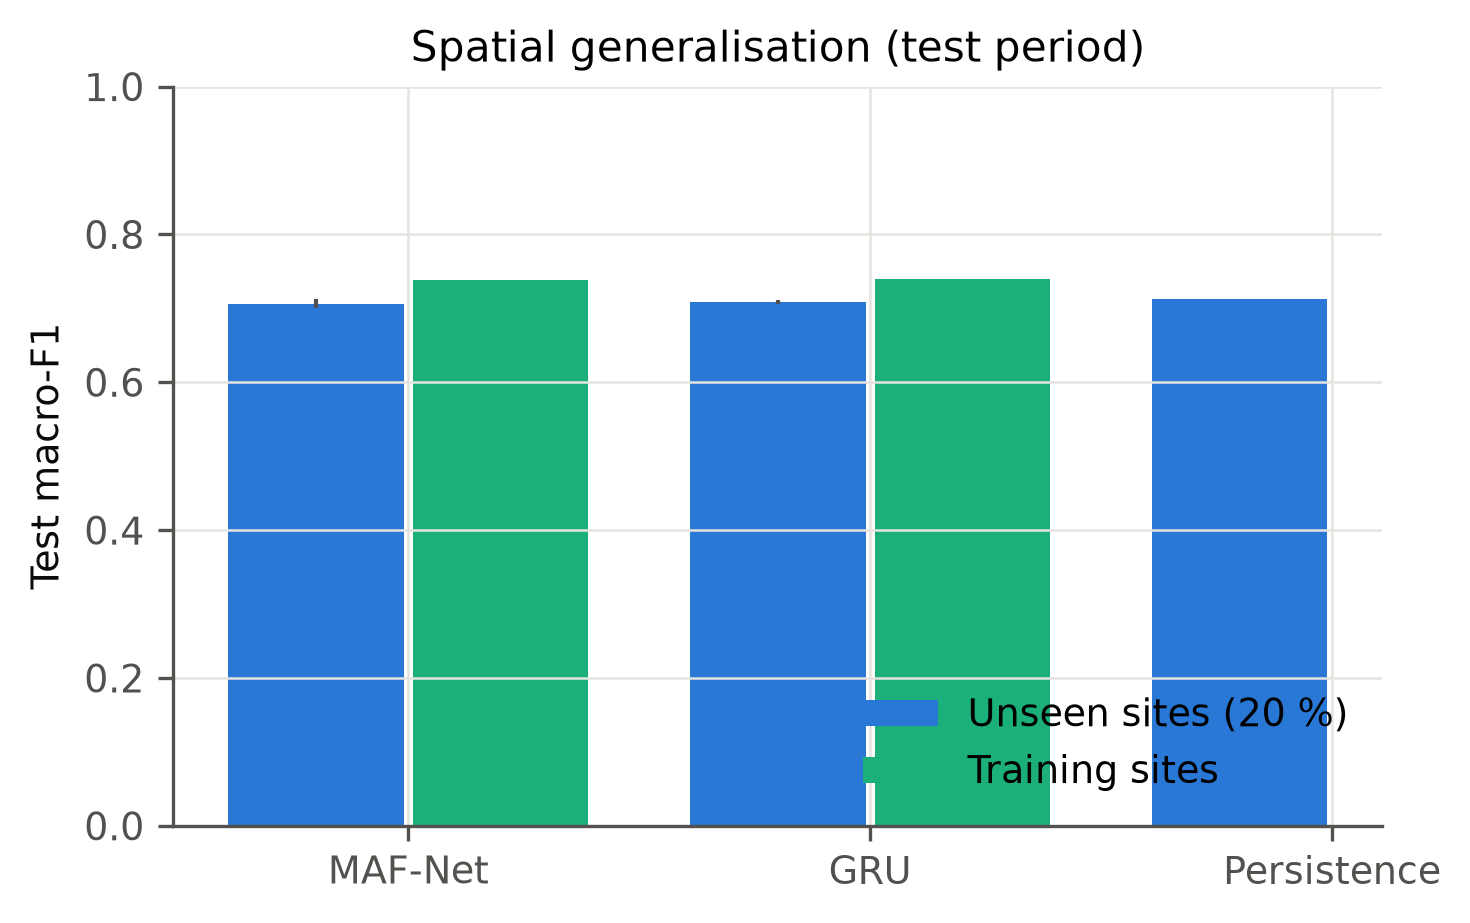

In [9]:
display(pd.read_csv(ROOT / "results/tables/horizons.csv")[["horizon","model","n_runs","accuracy","balanced_accuracy","macro_f1","macro_f1_std","roc_auc_macro_ovr"]].round(4))
show("results/figures/horizons.png", 520)
display(pd.read_csv(ROOT / "results/tables/spatial_holdout.csv").round(4))
show("results/figures/spatial_holdout.png", 480)

The held-out-site experiment retrains on 80 % of sites; sites are disjoint by construction
(`train_sites` filter on the site code) and the evaluation still uses only the test period, so
neither site identity nor time overlaps between training and evaluation.